# Description

Training for analyzing Octopus-slabs database with Pandas


# Page usage

* Checking how many entries we have with a certain filter.  


# Loading library

In [1]:
import pandas as pd
import octopus_slabs
from octopus_slabs.Libs.libPlotting import IndexFunctional
import os
import matplotlib.pyplot as plt
import numpy as np
OctopusData=os.environ["QuantumLaPruns"]
OctopusSources=os.environ["QuantumLaPsources"]
print(OctopusData, OctopusSources)

/home/thibault.derrien/Documents/octopus.data /home/thibault.derrien/Documents/octopus-slabs


# Going to the folder containing the database

In [2]:
# Localhost
# DatabasePath=OctopusData+"/03-Bulk3D/Si-1x1x1-k-24x24x1-Mesh0.434637008855-Mesh0.434637008855-T0e0-TB09/SingleColorSummary"

# BIATRI-SRV TB09 from backups (Draco, etc)
# DatabasePath=OctopusData+"/03-Bulk3D/01-ImportingTB09"

DatabasePath=OctopusData+"/03-Bulk3D/"
# DatabasePath=OctopusData+"/09-Au/"
%cd $DatabasePath

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D


# Database loading and quick analysis

In [28]:
# data=pd.read_csv("Database.csv", "\t", header=2)
data=pd.read_csv("SiComplete-2022-03-20-BiatriSrv-v2.2.1-WithToleranceOnField-WithAll.csv", "\t", header=2)
# data=pd.read_csv("SiComplete-2022-02-01-BiatriSrv-v2.2.1-WithToleranceOnField-WithAll.csv", "\t", header=2)
# data=pd.read_csv("SiComplete-2021-12-19-BiatriSrv-v2.2.1-WithToleranceOnField-WithAll.csv", "\t", header=2)
# data=pd.read_csv("2021-02-25-Au-AllData-Database-v2.1.2.csv", "\t", header=2)

data=data.rename(columns={"##JobID": "JobID"})
# data=data.convert_dtypes()
datafull=data
data.describe(include="all")
data.dtypes


JobID                           float64
RunDate                         float64
kgrid                           float64
realmesh                        float64
lambda1                         float64
tau1                            float64
Efield1                         float64
PolarizationAngle               float64
CEP1                            float64
lambda2                         float64
tau2                            float64
Efield2                         float64
CEP2                            float64
delay                           float64
CrossPolar                      float64
TheoryLevel                     float64
InducedFields                   float64
ProbeFieldAmplitude_AU          float64
ProbeFieldDelay_s               float64
Functional                      float64
FrozenHxc                       float64
MoveIon                         float64
NeMax                           float64
NeFinal                         float64
VirtualOscillations             float64


# Database filtering

In [29]:
data=datafull
data=data[data.Functional==IndexFunctional["TB09"]] #0: LDA, #3: TB09, #2: GGA, #1: MGGA
data=data[data.kgrid>=24]
data

,JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
2191,108831.0,20220210.0,40.0,0.434637,2.237000e-06,1.118420e-14,3.000000e+09,0.000000,0.0,2.237000e-06,...,0.0,0.130511,-1.063139e+14,5.605595e+26,5.001833e+40,5.012066e+40,1.0,0.0,1875.00,924.740368
2192,107048.0,20220208.0,40.0,0.434637,2.237000e-06,1.118420e-14,1.400000e+09,0.000000,0.0,2.237000e-06,...,0.0,0.000607,1.336902e+12,3.888609e+24,3.240066e+38,3.476877e+38,1.0,0.0,2000.00,924.740368
2193,108832.0,20220212.0,40.0,0.434637,2.237000e-06,1.118420e-14,9.000000e+09,0.000000,0.0,2.237000e-06,...,0.0,34.156830,7.707263e+15,4.725361e+28,4.225342e+42,4.225033e+42,1.0,0.0,1250.00,924.740368
2194,597659.0,20220309.0,40.0,0.434637,2.237000e-06,1.118420e-14,1.400000e+09,0.000000,0.0,2.237000e-06,...,0.0,0.000503,-7.747341e+11,0.000000e+00,2.677097e+38,0.000000e+00,5.0,0.0,2000.00,0.000000
2195,598340.0,20220316.0,40.0,0.434637,2.237000e-06,2.796053e-14,1.400000e+09,0.000000,0.0,2.237000e-06,...,0.0,0.000937,-7.549841e+13,0.000000e+00,2.005677e+38,0.000000e+00,5.0,0.0,3625.00,0.000000
2212,18876302.0,20200510.0,24.0,0.377945,8.000000e-07,3.000000e-14,0.000000e+00,0.000000,0.0,8.000000e-07,...,0.0,0.000000,-6.521269e+12,0.000000e+00,3.151506e+42,0.000000e+00,1.0,0.0,1375.00,0.000000
2213,18876301.0,20200510.0,24.0,0.377945,8.000000e-07,3.000000e-14,0.000000e+00,0.000000,0.0,8.000000e-07,...,0.0,0.000000,2.881719e+13,0.000000e+00,6.502426e+42,0.000000e+00,1.0,0.0,750.00,0.000000
2214,397863.0,20210317.0,24.0,0.434637,8.000000e-07,2.000000e-14,9.500000e+09,0.000000,0.0,8.000000e-07,...,0.0,62.685540,3.507795e+15,7.199475e+28,3.599386e+42,3.599737e+42,3.0,2.0,2028.75,937.147441
2215,397862.0,20210317.0,24.0,0.434637,8.000000e-07,2.000000e-14,9.000000e+09,0.000000,0.0,8.000000e-07,...,0.0,51.469468,2.327260e+15,6.467043e+28,3.232939e+42,3.233521e+42,3.0,2.0,2028.75,937.147441
2216,397856.0,20210317.0,24.0,0.434637,8.000000e-07,2.000000e-14,1.200000e+09,0.000000,0.0,8.000000e-07,...,0.0,0.013047,-1.156147e+14,7.351976e+25,3.676155e+39,3.675988e+39,3.0,2.0,2028.75,937.147441


In [45]:
data=data[data.lambda1==1030e-9]

In [46]:
print(set(data.lambda1))
print(set(data.tau1))

{1.03e-06}
{1.03071305416229e-14}


In [37]:
#data=data[data.CEP1==0]; 
#data=data[data.STH==3]; 
data=data[data.InducedFields==0]
data

,JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
2220,397855.0,20210317.0,24.0,0.434637,8.000000e-07,2.000000e-14,1.100000e+09,0.000000,0.0,8.000000e-07,...,0.0,0.008727,-1.022687e+14,5.061854e+25,2.530784e+39,2.530927e+39,3.0,2.0,2028.75,937.147441
2216,397856.0,20210317.0,24.0,0.434637,8.000000e-07,2.000000e-14,1.200000e+09,0.000000,0.0,8.000000e-07,...,0.0,0.013047,-1.156147e+14,7.351976e+25,3.676155e+39,3.675988e+39,3.0,2.0,2028.75,937.147441
2221,397857.0,20210317.0,24.0,0.434637,8.000000e-07,2.000000e-14,1.300000e+09,0.000000,0.0,8.000000e-07,...,0.0,0.019127,-1.302037e+14,1.051407e+26,5.257609e+39,5.257035e+39,3.0,2.0,2028.75,937.147441
2217,397858.0,20210317.0,24.0,0.434637,8.000000e-07,2.000000e-14,1.400000e+09,0.000000,0.0,8.000000e-07,...,0.0,0.027527,-1.461968e+14,1.481875e+26,7.410402e+39,7.409373e+39,3.0,2.0,2028.75,937.147441
2219,397859.0,20210317.0,24.0,0.434637,8.000000e-07,2.000000e-14,6.500000e+09,0.000000,0.0,8.000000e-07,...,0.0,17.039258,1.355286e+14,3.452967e+28,1.726436e+42,1.726484e+42,3.0,2.0,2028.75,937.147441
2218,397860.0,20210317.0,24.0,0.434637,8.000000e-07,2.000000e-14,7.000000e+09,0.000000,0.0,8.000000e-07,...,0.0,22.556982,7.701757e+14,4.111291e+28,2.056079e+42,2.055645e+42,3.0,2.0,2028.75,937.147441
2222,397861.0,20210317.0,24.0,0.434637,8.000000e-07,2.000000e-14,8.000000e+09,0.000000,0.0,8.000000e-07,...,0.0,34.985575,2.042783e+15,5.276971e+28,2.638661e+42,2.638486e+42,3.0,2.0,2028.75,937.147441
2215,397862.0,20210317.0,24.0,0.434637,8.000000e-07,2.000000e-14,9.000000e+09,0.000000,0.0,8.000000e-07,...,0.0,51.469468,2.327260e+15,6.467043e+28,3.232939e+42,3.233521e+42,3.0,2.0,2028.75,937.147441
2214,397863.0,20210317.0,24.0,0.434637,8.000000e-07,2.000000e-14,9.500000e+09,0.000000,0.0,8.000000e-07,...,0.0,62.685540,3.507795e+15,7.199475e+28,3.599386e+42,3.599737e+42,3.0,2.0,2028.75,937.147441
2235,114976.0,20220316.0,24.0,0.434637,1.030000e-06,1.030713e-14,1.000000e+09,0.000000,0.0,1.030000e-06,...,0.0,0.001920,1.886592e+14,1.236265e+25,1.198038e+39,1.199426e+39,3.0,2.0,1590.00,568.147904


In [38]:
data=data.sort_values(["lambda1", "tau1", "Efield1", "Efield2", "PolarizationAngle", "kgrid", "realmesh"], ascending=True)
datafull=data

In [39]:
datafull

,JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
2220,397855.0,20210317.0,24.0,0.434637,8.000000e-07,2.000000e-14,1.100000e+09,0.000000,0.0,8.000000e-07,...,0.0,0.008727,-1.022687e+14,5.061854e+25,2.530784e+39,2.530927e+39,3.0,2.0,2028.75,937.147441
2216,397856.0,20210317.0,24.0,0.434637,8.000000e-07,2.000000e-14,1.200000e+09,0.000000,0.0,8.000000e-07,...,0.0,0.013047,-1.156147e+14,7.351976e+25,3.676155e+39,3.675988e+39,3.0,2.0,2028.75,937.147441
2221,397857.0,20210317.0,24.0,0.434637,8.000000e-07,2.000000e-14,1.300000e+09,0.000000,0.0,8.000000e-07,...,0.0,0.019127,-1.302037e+14,1.051407e+26,5.257609e+39,5.257035e+39,3.0,2.0,2028.75,937.147441
2217,397858.0,20210317.0,24.0,0.434637,8.000000e-07,2.000000e-14,1.400000e+09,0.000000,0.0,8.000000e-07,...,0.0,0.027527,-1.461968e+14,1.481875e+26,7.410402e+39,7.409373e+39,3.0,2.0,2028.75,937.147441
2219,397859.0,20210317.0,24.0,0.434637,8.000000e-07,2.000000e-14,6.500000e+09,0.000000,0.0,8.000000e-07,...,0.0,17.039258,1.355286e+14,3.452967e+28,1.726436e+42,1.726484e+42,3.0,2.0,2028.75,937.147441
2218,397860.0,20210317.0,24.0,0.434637,8.000000e-07,2.000000e-14,7.000000e+09,0.000000,0.0,8.000000e-07,...,0.0,22.556982,7.701757e+14,4.111291e+28,2.056079e+42,2.055645e+42,3.0,2.0,2028.75,937.147441
2222,397861.0,20210317.0,24.0,0.434637,8.000000e-07,2.000000e-14,8.000000e+09,0.000000,0.0,8.000000e-07,...,0.0,34.985575,2.042783e+15,5.276971e+28,2.638661e+42,2.638486e+42,3.0,2.0,2028.75,937.147441
2215,397862.0,20210317.0,24.0,0.434637,8.000000e-07,2.000000e-14,9.000000e+09,0.000000,0.0,8.000000e-07,...,0.0,51.469468,2.327260e+15,6.467043e+28,3.232939e+42,3.233521e+42,3.0,2.0,2028.75,937.147441
2214,397863.0,20210317.0,24.0,0.434637,8.000000e-07,2.000000e-14,9.500000e+09,0.000000,0.0,8.000000e-07,...,0.0,62.685540,3.507795e+15,7.199475e+28,3.599386e+42,3.599737e+42,3.0,2.0,2028.75,937.147441
2235,114976.0,20220316.0,24.0,0.434637,1.030000e-06,1.030713e-14,1.000000e+09,0.000000,0.0,1.030000e-06,...,0.0,0.001920,1.886592e+14,1.236265e+25,1.198038e+39,1.199426e+39,3.0,2.0,1590.00,568.147904


In [34]:
datafull.var()

JobID                           3.092255e+10
RunDate                         2.518448e+07
kgrid                           4.578462e+01
realmesh                        7.901251e-32
lambda1                         9.597735e-13
tau1                            2.660673e-29
Efield1                         3.674233e+20
PolarizationAngle               5.694003e-02
CEP1                            0.000000e+00
lambda2                         9.597735e-13
tau2                            2.660673e-29
Efield2                         0.000000e+00
CEP2                            0.000000e+00
delay                           1.117788e-32
CrossPolar                      5.694003e-02
TheoryLevel                     0.000000e+00
InducedFields                   0.000000e+00
ProbeFieldAmplitude_AU          0.000000e+00
ProbeFieldDelay_s                        NaN
Functional                      0.000000e+00
FrozenHxc                       0.000000e+00
MoveIon                         0.000000e+00
NeMax     

In [40]:
from octopus_slabs.Libs.libPlotting import PulseTypeID
# print(PulseTypeID['SinSquared'])
datatmp=datafull
datatmp=data[data.PolarizationAngle==0]
# datatmp=datatmp[np.fabs(datatmp.lambda1-1.367968e-6)<1e-9] #Bicolor runs
datatmp=datatmp[np.fabs(datatmp.lambda1-1030e-9)<1e-9] #Pharos, but direct transition
# datatmp=datatmp[np.fabs(datatmp.lambda1-2.65625e-6)<1e-9] #Kozak 2000 nm
datatmp=datatmp[datatmp.Efield2==0]
# datatmp=datatmp[datatmp.Efield1==3E9]
datatmp=datatmp[datatmp.CEP1==0]
datatmp=datatmp[datatmp.STH==PulseTypeID['StH']]
datatmp=datatmp[np.fabs(datatmp.tau1-20E-15)<1E-15]
datatmp=datatmp[datatmp.RiseCycles==2]
datatmp=datatmp[datatmp.FrozenHxc==0]
# datatmp=datatmp[datatmp.PolarizationAngle==0]
data20 = datatmp

# plt.loglog(Efield, Wpi, "v")
# plt.semilogx(JobID, RunDate_t)
# datafield1=datatmp[datatmp.Efield1==3E9]
# datafield2=datatmp[datatmp.Efield1==9E9]

In [41]:
datatmp=datafull
datatmp=data[data.PolarizationAngle==0]
# datatmp=datatmp[np.fabs(datatmp.lambda1-1.367968e-6)<1e-9] #Bicolor runs
datatmp=datatmp[np.fabs(datatmp.lambda1-1030e-9)<1e-9] #Pharos, but direct transition
# datatmp=datatmp[np.fabs(datatmp.lambda1-2.65625e-6)<1e-9] #Kozak 2000 nm
datatmp=datatmp[datatmp.Efield2==0]
# datatmp=datatmp[datatmp.Efield1==3E9]
datatmp=datatmp[datatmp.CEP1==0]
datatmp=datatmp[datatmp.STH==PulseTypeID['StH']]
datatmp=datatmp[np.fabs(datatmp.tau1-10E-15)<1E-15]
datatmp=datatmp[datatmp.FrozenHxc==0]
datatmp=datatmp[datatmp.PolarizationAngle==0]
data10 = datatmp

In [42]:
datatmp=datafull
datatmp=data[data.PolarizationAngle==0]
# datatmp=datatmp[np.fabs(datatmp.lambda1-1.367968e-6)<1e-9] #Bicolor runs
datatmp=datatmp[np.fabs(datatmp.lambda1-1030e-9)<1e-9] #Pharos, but direct transition
# datatmp=datatmp[np.fabs(datatmp.lambda1-2.65625e-6)<1e-9] #Kozak 2000 nm
datatmp=datatmp[datatmp.Efield2==0]
# datatmp=datatmp[datatmp.Efield1==3E9]
datatmp=datatmp[datatmp.CEP1==0]
datatmp=datatmp[datatmp.STH==PulseTypeID['StH']]
datatmp=datatmp[np.fabs(datatmp.tau1-30E-15)<1E-15]
datatmp=datatmp[datatmp.FrozenHxc==0]
# datatmp=datatmp[datatmp.PolarizationAngle==0]
data30 = datatmp

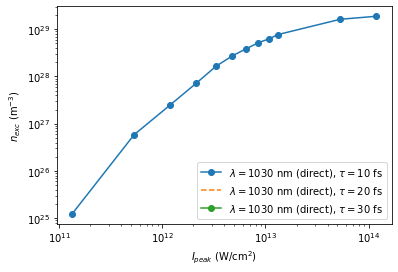

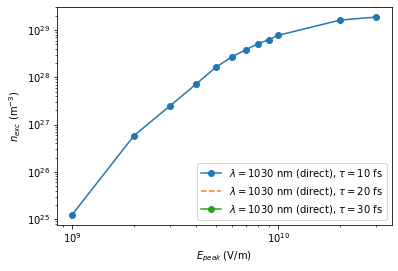

In [43]:
from scipy.constants import c, epsilon_0
plt.figure()
plt.loglog(1E-4*0.5*c*epsilon_0*data10.Efield1**2, data10.N_exc_afterpulse, "-o", label=r"$\lambda=1030$ nm (direct), $\tau=$10 fs")
plt.loglog(1E-4*0.5*c*epsilon_0*data20.Efield1**2, data20.N_exc_afterpulse, "--", label=r"$\lambda=1030$ nm (direct), $\tau=$20 fs")
plt.loglog(1E-4*0.5*c*epsilon_0*data30.Efield1**2, data30.N_exc_afterpulse, "-o", label=r"$\lambda=1030$ nm (direct), $\tau=$30 fs")
# plt.xlabel(r"$E_{peak}$ (V/m)")
plt.xlabel(r"$I_{peak}$ (W/cm$^{2}$)")
# plt.xlabel(r"$\phi$ (deg)")
# plt.ylabel(r"$W_{\mathrm{PI}}$")
plt.ylabel(r"$n_{exc}$ (m$^{-3}$)")
plt.legend()
plt.show()

plt.figure()
plt.loglog(data10.Efield1, data10.N_exc_afterpulse, "-o", label=r"$\lambda=1030$ nm (direct), $\tau=$10 fs")
plt.loglog(data20.Efield1, data20.N_exc_afterpulse, "--", label=r"$\lambda=1030$ nm (direct), $\tau=$20 fs")
plt.loglog(data30.Efield1, data30.N_exc_afterpulse, "-o", label=r"$\lambda=1030$ nm (direct), $\tau=$30 fs")
plt.xlabel(r"$E_{peak}$ (V/m)")
# plt.xlabel(r"$I_{peak}$ (W/cm$^{2}$)")
# plt.xlabel(r"$\phi$ (deg)")
# plt.ylabel(r"$W_{\mathrm{PI}}$")
# plt.xlim([2E8,3E8]))
plt.ylabel(r"$n_{exc}$ (m$^{-3}$)")
plt.legend()
plt.show()

  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


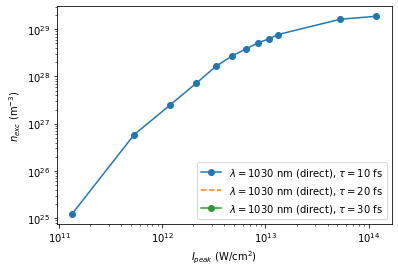

  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


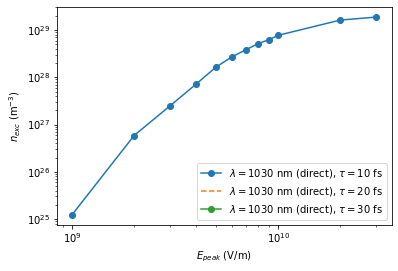

In [44]:
from scipy.constants import c, epsilon_0
plt.figure()
plt.loglog(1E-4*0.5*c*epsilon_0*data10.Efield1**2, data10.NeFinal, "-o", label=r"$\lambda=1030$ nm (direct), $\tau=$10 fs")
plt.loglog(1E-4*0.5*c*epsilon_0*data20.Efield1**2, data20.NeFinal, "--", label=r"$\lambda=1030$ nm (direct), $\tau=$20 fs")
plt.loglog(1E-4*0.5*c*epsilon_0*data30.Efield1**2, data30.NeFinal, "-o", label=r"$\lambda=1030$ nm (direct), $\tau=$30 fs")
# plt.xlabel(r"$E_{peak}$ (V/m)")
plt.xlabel(r"$I_{peak}$ (W/cm$^{2}$)")
# plt.xlabel(r"$\phi$ (deg)")
# plt.ylabel(r"$W_{\mathrm{PI}}$")
plt.ylabel(r"$n_{exc}$ (m$^{-3}$)")
plt.legend()
plt.savefig("1030nm-TB09-ExcitationRateLDA-NonNormalized.eps")
plt.show()

plt.figure()
plt.loglog(data10.Efield1, data10.NeFinal, "-o", label=r"$\lambda=1030$ nm (direct), $\tau=$10 fs")
plt.loglog(data20.Efield1, data20.NeFinal, "--", label=r"$\lambda=1030$ nm (direct), $\tau=$20 fs")
plt.loglog(data30.Efield1, data30.NeFinal, "-o", label=r"$\lambda=1030$ nm (direct), $\tau=$30 fs")
plt.xlabel(r"$E_{peak}$ (V/m)")
# plt.xlabel(r"$I_{peak}$ (W/cm$^{2}$)")
# plt.xlabel(r"$\phi$ (deg)")
# plt.ylabel(r"$W_{\mathrm{PI}}$")
# plt.xlim([2E8,3E8]))
plt.ylabel(r"$n_{exc}$ (m$^{-3}$)")
plt.legend()
plt.savefig("1030nm-TB09-AbsorbedEnergyLDA-NonNormalized.eps")
plt.show()

In [16]:
datatest=data30[data30.Efield1<=3E8]
datatest=datatest[datatest.Efield1>=2E8]
datatest.all()

JobID                            True
RunDate                          True
kgrid                            True
realmesh                         True
lambda1                          True
tau1                             True
Efield1                          True
PolarizationAngle               False
CEP1                            False
lambda2                          True
tau2                             True
Efield2                         False
CEP2                            False
delay                           False
CrossPolar                      False
TheoryLevel                      True
InducedFields                   False
ProbeFieldAmplitude_AU          False
ProbeFieldDelay_s                True
Functional                      False
FrozenHxc                       False
MoveIon                         False
NeMax                            True
NeFinal                          True
VirtualOscillations              True
FinalCurrent                     True
MaxCurrent_A

In [25]:
# datatest=datatest[datatest.JobID>8.47E6]

In [17]:
datatest.var()

JobID                           4.302006e+12
RunDate                         4.758607e+07
kgrid                           0.000000e+00
realmesh                        5.007714e-27
lambda1                         4.616042e-44
tau1                            4.099869e-59
Efield1                         1.470588e+14
PolarizationAngle               0.000000e+00
CEP1                            0.000000e+00
lambda2                         4.616042e-44
tau2                            4.099869e-59
Efield2                         0.000000e+00
CEP2                            0.000000e+00
delay                           3.466387e-33
CrossPolar                      0.000000e+00
TheoryLevel                     0.000000e+00
InducedFields                   0.000000e+00
ProbeFieldAmplitude_AU          0.000000e+00
ProbeFieldDelay_s                        NaN
Functional                      0.000000e+00
FrozenHxc                       0.000000e+00
MoveIon                         0.000000e+00
NeMax     

In [18]:
set(datatest.Efield1)

{200000000.0, 250000000.0, 300000000.0}

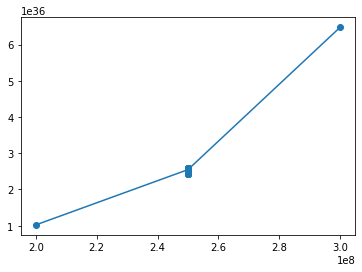

In [24]:
plt.figure()
plt.plot(datatest.Efield1, datatest.Wpi, "-o", label=r"$\lambda=1030$ nm (direct), $\tau=$30 fs")
# plt.xlim([8.475E6,8.525E6])
plt.show()

In [35]:
datatest=datatest[datatest.JobID<8.52E6]

In [20]:
datatest

,JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
2451,591641.0,20220114.0,24.0,0.434637,0.000001,3.000000e-14,200000000.0,0.0,0.0,0.000001,...,0.000027,0.000022,-2.065277e+13,4.434591e+22,1.020874e+36,1.478197e+36,3.0,2.0,2892.5,1382.278166
1251,9398764.0,20190819.0,24.0,0.434637,0.000001,3.000000e-14,250000000.0,0.0,0.0,0.000001,...,-0.000037,0.000039,6.132310e+13,3.994232e+25,2.547052e+36,1.331411e+39,3.0,2.0,3250.0,1382.278166
1259,9398862.0,20190825.0,24.0,0.434637,0.000001,3.000000e-14,250000000.0,0.0,0.0,0.000001,...,-0.000037,0.000039,-6.554790e+13,3.994232e+25,2.587700e+36,1.331411e+39,3.0,2.0,3125.0,1382.278166
1263,9398886.0,20190828.0,24.0,0.434637,0.000001,3.000000e-14,250000000.0,0.0,0.0,0.000001,...,-0.000037,0.000039,-4.797021e+13,3.994232e+25,2.507337e+36,1.331411e+39,3.0,2.0,3375.0,1382.278166
1271,9398782.0,20190820.0,24.0,0.434637,0.000001,3.000000e-14,250000000.0,0.0,0.0,0.000001,...,-0.000037,0.000039,-4.797021e+13,3.994232e+25,2.507337e+36,1.331411e+39,3.0,2.0,3375.0,1382.278166
1273,9398827.0,20190822.0,24.0,0.434637,0.000001,3.000000e-14,250000000.0,0.0,0.0,0.000001,...,-0.000037,0.000039,-1.235339e+13,3.994232e+25,2.431424e+36,1.331411e+39,3.0,2.0,3625.0,1382.278166
1280,9398877.0,20190827.0,24.0,0.434637,0.000001,3.000000e-14,250000000.0,0.0,0.0,0.000001,...,-0.000037,0.000039,-1.235339e+13,3.994232e+25,2.431424e+36,1.331411e+39,3.0,2.0,3625.0,1382.278166
1283,9398817.0,20190822.0,24.0,0.434637,0.000001,3.000000e-14,250000000.0,0.0,0.0,0.000001,...,-0.000037,0.000039,-6.554790e+13,3.994232e+25,2.587700e+36,1.331411e+39,3.0,2.0,3125.0,1382.278166
1284,9398776.0,20190819.0,24.0,0.434637,0.000001,3.000000e-14,250000000.0,0.0,0.0,0.000001,...,-0.000037,0.000039,6.132310e+13,3.994232e+25,2.547052e+36,1.331411e+39,3.0,2.0,3250.0,1382.278166
1297,9398796.0,20190820.0,24.0,0.434637,0.000001,3.000000e-14,250000000.0,0.0,0.0,0.000001,...,-0.000037,0.000039,-6.554790e+13,3.994232e+25,2.587700e+36,1.331411e+39,3.0,2.0,3125.0,1382.278166
